# **실습 개요**

여러분은 이커머스 기업의 **마케팅 데이터 분석가**입니다. <br>
회사는 매달 모바일 광고, SNS 광고, 오프라인(매장) 채널에 마케팅 예산과 인력을 투입하고 있고, <br>
이 활동이 실제 **멤버십 가입**으로 이어지는지를 예측하는 모델을 만들려고 합니다.

다만 모바일 광고비와 SNS 광고비는 같은 캠페인 기간에 함께 늘고 줄어드는 경향이 있어 <br>
강한 상관관계(다중공선성)를 갖고 있습니다. 이런 상황에서 변수를 어떻게 다루느냐에 따라 모델의 신뢰도와 성능이 달라집니다.

## **데이터셋 설명**

25개 시점(캠페인 단위) 동안의 채널별 마케팅 지표와 실제 멤버십 가입 여부를 담은 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| mobile | 모바일 광고비 |
| sns | SNS 광고비 |
| offline | 오프라인(매장) 방문자 수 (명) |
| membership | **[target]** 멤버십 가입 여부 (1=가입, 0=미가입) |

## **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/ad.csv

## **1. 데이터 살펴보기**

**Q1. 데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/ad.csv")
df.head()

,mobile,sns,offline,membership
0,551.4,567.9,2122,0
1,258.4,230.4,2104,0
2,377.3,296.7,4632,0
3,584.3,452.3,3028,1
4,729.1,662.4,3068,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   mobile      25 non-null     float64
 1   sns         25 non-null     float64
 2   offline     25 non-null     int64  
 3   membership  25 non-null     int64  
dtypes: float64(2), int64(2)
memory usage: 932.0 bytes


In [4]:
df.describe()

,mobile,sns,offline,membership
count,25.000000,25.000000,25.00000,25.000000
mean,524.664000,443.272000,2828.08000,0.440000
std,145.580413,170.070683,794.85255,0.506623
min,258.400000,121.700000,984.00000,0.000000
25%,419.700000,350.100000,2222.00000,0.000000
50%,551.400000,445.000000,3014.00000,0.000000
75%,616.800000,575.900000,3141.00000,1.000000
max,759.700000,674.100000,4632.00000,1.000000


## **2. 데이터 분리하기**

**Q1. 'membership'을 라벨로 데이터를 train과 test 데이터로 분리하세요.**
- 비율: 7(학습):3(테스트)
- random_state = 32
- stratify 옵션을 사용합니다.

In [11]:
# code here
from sklearn.model_selection import train_test_split

X = df.drop("membership", axis = 1)
y = df["membership"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=32, stratify=y)

(17, 3)

## **3. 모델링 1**

**Q1. 로지스틱 회귀 모델을 생성하고, 학습시킵니다.**

In [13]:
# code here

from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

**Q2. 학습된 모델로 테스트 데이터의 값을 예측합니다.**

In [14]:
# code here
y_pred = model.predict(X_test)


**Q3. 모델을 평가합니다.**

In [15]:
# code here
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
def evaluate_model(y_true, y_pred):
    print(f"accuray: {accuracy_score(y_test, y_pred)}")
    print(classification_report(y_true, y_pred))
    plt.figure(figsize=(5,3))
    sns.heatmap(confusion_matrix(y_test, y_pred), cmap = "Blues", annot = True)
    plt.show()

accuray: 0.875
              precision    recall  f1-score   support

           0       0.80      1.00      0.89         4
           1       1.00      0.75      0.86         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8



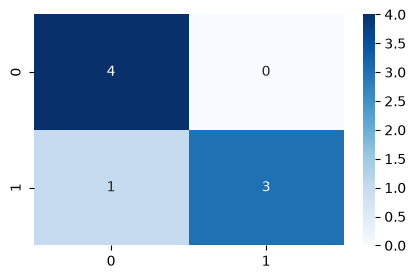

In [18]:
evaluate_model(y_test, y_pred)

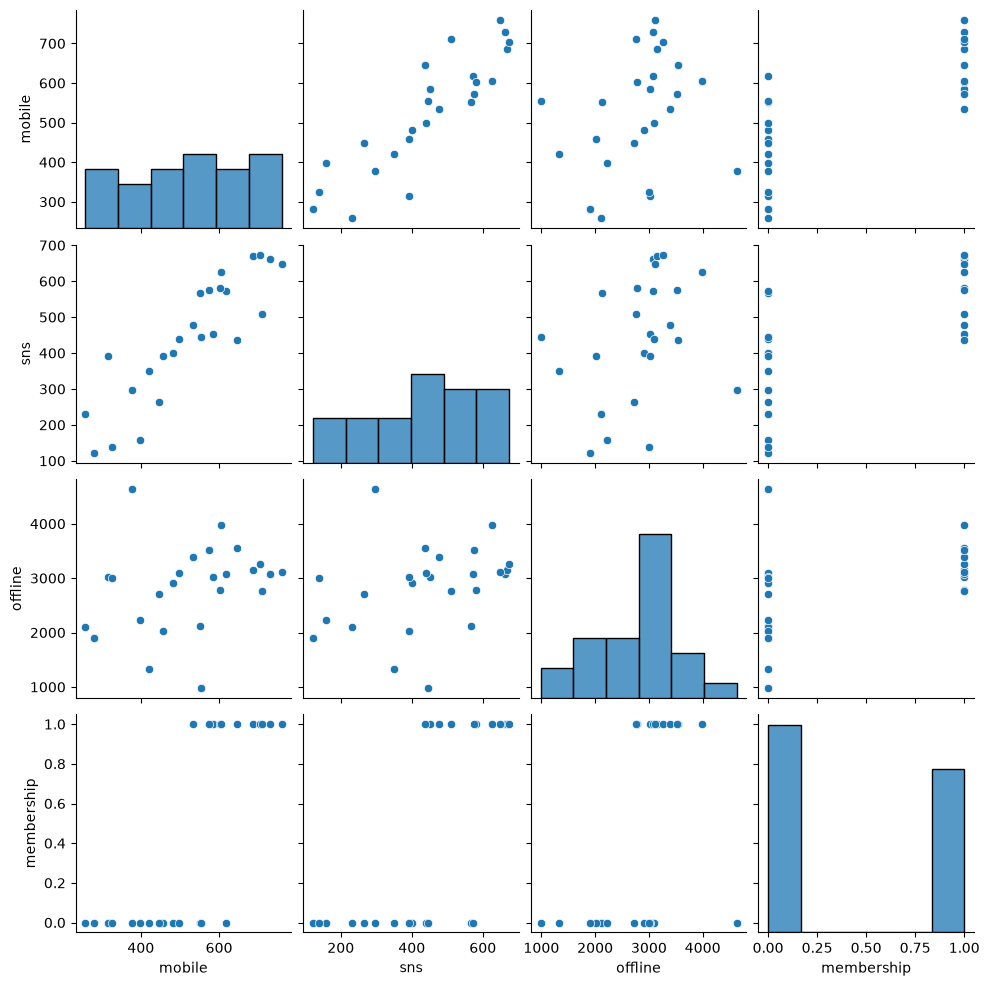

In [19]:
sns.pairplot(df)

## **3. 다중공선성 확인하기**

**Q1. train 데이터의 상관행렬을 시각화하세요.**

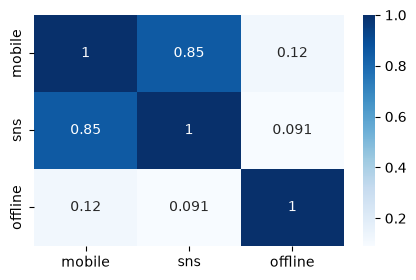

In [ ]:
# code here

# 상관 행렬 (corrleation matrix): 각 변수간의 관계를 보기 위해 사용하는 시각화(통계)
# 라벨 없이 보게 되면 -> 각 변수끼리 얼머나 큰 영향을 미치는지를 확인할 수 있다.
# 좋은 데이터: 모든 특징이 최대한 독립적이야 좋다.

# 상관 행렬의 결과
# 1: 완벽 비례
# 0: 관계 없음
# -1: 완벽 반비례

# 공선성 판단 기준
# 0~ 0.5: 크게 신경 쓸 필요 없음
# 0.5 ~ 0.7: 둘이 그래도 꽤 서로 영향이 있는 관계
# 0.7 이상: 둘이 아주 높은 상관관계에 있다. -> 다중공선성이라는 것을 의심

# 다중공선성: multicolinearity
# 하나의 변수를 가지고 다른 변수의 값을 예측 가능한 상태
# perfect multicolinearity : 완벽하게 예측이 가능한 상황 -> one hot encoding (drop 하는 이유)
# multicolinearity를 처리해야하는 이유: 같은 변수 -> 너무 발운권이 심해짐 
# 특히나 선형 모델이나 연속적인 값(regression) 을 처리해야하는 경우에는 필수




plt.figure(figsize=(5,3))
sns.heatmap(X_train.corr(), annot=True, cmap="Blues")
plt.show()

**Q2. train 데이터와 라벨까지 포함한 상관행렬을 시각화하세요.**

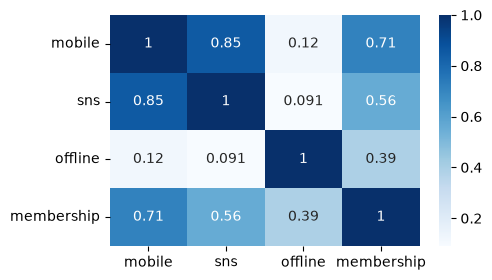

In [23]:
# code here

X_train_copy = X_train.copy()
X_train_copy["membership"] = y_train

plt.figure(figsize=(5,3))
sns.heatmap(X_train_copy.corr(), annot=True, cmap="Blues")
plt.show()

## **모델링 2**

**Q1. 상관관계가 높은 컬럼 중 하나를 드랍합니다.**
- 드랍시에는 상관 관계가 있는 두 특징 중, 결과에 영향을 덜 끼치는 컬럼을 드랍합니다.

In [24]:
# code here
# feature engineering dimensionality 방법 2가지
# 1. feature selection
# 상관행렬을 확인하고, 높은 상관관계를 보이는 변수들을 찾아서
# 라벨에 가장 큰 영향을 주는 애를 하나를 놔두고 나머지를 drop

# 2. feature extraction
# 관계가 비슷한 애들을 모아서 새로운 특성으로 하나로 압축하거나 묶는다.
# PCA

# mobile이 라벨에 더 큰 영향을 줌
X_train = X_train.drop("sns", axis = 1)

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [25]:
X_test = X_test.drop("sns", axis = 1)

In [26]:
y_pred = model.predict(X_test)

accuray: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



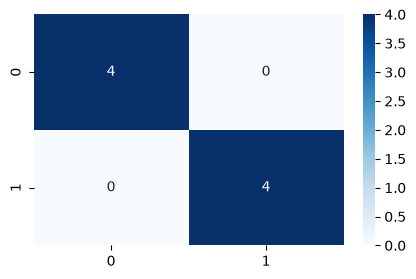

In [27]:
evaluate_model(y_test, y_pred)

**Q2. 로지스틱 회귀 모델을 학습 시킵니다.**

In [8]:
# code here

**Q3. 학습된 모델로 test 데이터의 예측 결과를 구합니다.**

In [9]:
# code here

**Q4. 모델의 성능을 평가합니다.**

In [10]:
# code here